# Olist orders: exploratory data analysis

Source: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).
One row is one order. This notebook uses only the supplied orders table, preserves the original CSV,
and supports the dashboard decisions in README.md. All displayed outcomes are historical snapshot outcomes.
Default purchase cohort: January 2017 through August 2018.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

source = Path("olist_orders_dataset.csv")
raw = pd.read_csv(source)
df = raw.copy()
date_columns = list(df.columns[3:])
for column in date_columns:
    df[column] = pd.to_datetime(df[column], errors="coerce")
print("Shape:", df.shape)
print("CSV bytes:", source.stat().st_size)
print("Raw column types:\n", raw.dtypes.to_string())
print("Analysis column types:\n", df.dtypes.to_string())
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate order IDs:", int(df.order_id.duplicated().sum()))
print("Missing values:\n", df.isna().sum().to_string())
parse_failures = {c: int((raw[c].notna() & df[c].isna()).sum()) for c in date_columns}
print("Non-null timestamps that failed parsing:", parse_failures)
print("Order statuses:\n", df.order_status.value_counts().to_string())
for column in date_columns:
    print(column, "range:", df[column].min(), "to", df[column].max())


Shape: (99441, 8)
CSV bytes: 17654914
Raw column types:
 order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
Analysis column types:
 order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
Duplicate rows: 0
Duplicate order IDs: 0
Missing values:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at            

## Delivery measures and missingness

A delivery is late only if its actual **calendar date** exceeds its estimated calendar date.
The estimated timestamps are all midnight, so timestamp comparison would incorrectly classify deliveries on the promised day.
Duration measures use continuous 24-hour days. Missing delivery dates are not zero-duration or on-time deliveries.
KPI eligibility requires delivered status, complete purchase/actual/estimated timestamps, and nonnegative end-to-end duration.


In [2]:
df["delivery_days"] = (df.order_delivered_customer_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
df["late_days"] = (df.order_delivered_customer_date.dt.normalize() - df.order_estimated_delivery_date.dt.normalize()).dt.days
df["purchase_month"] = df.order_purchase_timestamp.dt.to_period("M")
eligible = (
    df.order_status.eq("delivered")
    & df.order_purchase_timestamp.notna()
    & df.order_delivered_customer_date.notna()
    & df.order_estimated_delivery_date.notna()
    & df.delivery_days.ge(0)
)
valid = df.loc[eligible].copy()
valid["late"] = valid.late_days.gt(0)
print("All estimated timestamps are midnight:", df.order_estimated_delivery_date.eq(df.order_estimated_delivery_date.dt.normalize()).all())
print("Eligible deliveries:", len(valid))
print("Late deliveries:", int(valid.late.sum()))
print("Late delivery rate: {:.4%}".format(valid.late.mean()))
print("Promised-day deliveries:", int(valid.late_days.eq(0).sum()))
print("Incorrect timestamp-based late count:", int((valid.order_delivered_customer_date > valid.order_estimated_delivery_date).sum()))
print("Delivery duration distribution, days:\n", valid.delivery_days.describe(percentiles=[.5,.9,.95,.99]).to_string())
print("Delay days, late orders only:\n", valid.loc[valid.late, "late_days"].describe(percentiles=[.5,.9,.95,.99]).to_string())
print("Delivered status but missing actual date:", int((df.order_status.eq("delivered") & df.order_delivered_customer_date.isna()).sum()))
print("Other status with actual delivery date:", int((df.order_status.ne("delivered") & df.order_delivered_customer_date.notna()).sum()))


All estimated timestamps are midnight: True
Eligible deliveries: 96470
Late deliveries: 6534
Late delivery rate: 6.7731%
Promised-day deliveries: 1292
Incorrect timestamp-based late count: 7826
Delivery duration distribution, days:
 count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
50%         10.217477
90%         23.096377
95%         29.274046
99%         46.050262
max        209.628611
Delay days, late orders only:
 count    6534.000000
mean       10.620141
std        14.644955
min         1.000000
50%         7.000000
90%        22.000000
95%        31.000000
99%        71.340000
max       188.000000
Delivered status but missing actual date: 8
Other status with actual delivery date: 6


## Purchase cohorts and default period

The entire purchase range is September 4, 2016 to October 17, 2018.
Edge months have sparse observations, and November 2016 has no observations in this file.
The default period avoids these sparse edge months but does not prove complete market coverage.
Monthly rates use eventual delivered outcomes of orders **purchased** that month, not the rate of deliveries completed that month.


In [3]:
full_months = pd.period_range(df.purchase_month.min(), df.purchase_month.max(), freq="M")
purchase_counts = df.groupby("purchase_month").size().reindex(full_months, fill_value=0)
print("Orders by purchase month (zero means no records in this file):\n", purchase_counts.to_string())

period_mask = df.order_purchase_timestamp.ge("2017-01-01") & df.order_purchase_timestamp.lt("2018-09-01")
scope = df.loc[period_mask].copy()
default_valid = valid.loc[valid.order_purchase_timestamp.ge("2017-01-01") & valid.order_purchase_timestamp.lt("2018-09-01")].copy()
monthly = default_valid.groupby("purchase_month").agg(
    eligible_deliveries=("order_id", "size"),
    late_deliveries=("late", "sum"),
    median_delivery_days=("delivery_days", "median"),
).reindex(pd.period_range("2017-01", "2018-08", freq="M"))
monthly["late_rate_pct"] = monthly.late_deliveries / monthly.eligible_deliveries * 100
print("Default total orders:", len(scope))
print("Default eligible deliveries:", len(default_valid))
print("Default late deliveries:", int(default_valid.late.sum()))
print("Default late rate: {:.4%}".format(default_valid.late.mean()))
print("Default median delivery days: {:.6f}".format(default_valid.delivery_days.median()))
print("Monthly outcomes:\n", monthly.round(4).to_string())


Orders by purchase month (zero means no records in this file):
 2016-09       4
2016-10     324
2016-11       0
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M
Default total orders: 99092
Default eligible deliveries: 96203
Default late deliveries: 6531
Default late rate: 6.7888%
Default median delivery days: 10.209988
Monthly outcomes:
          eligible_deliveries  late_deliveries  median_delivery_days  late_rate_pct
2017-01                  750               22               10.7336         2.9333
2017-02                 1653               49               10.9712         2.9643
2017-03                 2546              116               10.1265         4.5562
2

## Stage durations: common sample, invalid sequences, association

Compare on-time and late orders using the same complete, nonnegative stage sample.
Exclude invalid stage records from stage comparisons only, preserving eligible end-to-end KPI records.
Stage medians must not be summed into an end-to-end median.
Differences suggest an investigation direction, not causality or responsibility of a particular carrier.


In [4]:
stages = {
    "approval_days": ("order_purchase_timestamp", "order_approved_at"),
    "handoff_days": ("order_approved_at", "order_delivered_carrier_date"),
    "transit_days": ("order_delivered_carrier_date", "order_delivered_customer_date"),
}
for name, (start, end) in stages.items():
    df[name] = (df[end] - df[start]).dt.total_seconds() / 86400
delivered = df.loc[df.order_status.eq("delivered")]
for name in stages:
    print(name, "missing:", int(delivered[name].isna().sum()), "negative:", int(delivered[name].lt(0).sum()))
stage_data = df.loc[period_mask & eligible & df[list(stages)].ge(0).all(axis=1)].copy()
stage_data["delivery_result"] = np.where(stage_data.late_days.gt(0), "Late", "On time")
stage_medians = stage_data.groupby("delivery_result")[list(stages)].median().reindex(["On time", "Late"])
print("Default common stage sample:", len(stage_data))
print("Excluded from stage chart:", len(default_valid)-len(stage_data))
print("Sample counts:\n", stage_data.groupby("delivery_result").size().to_string())
print("Median days by stage and outcome:\n", stage_medians.round(6).to_string())


approval_days missing: 14 negative: 0
handoff_days missing: 16 negative: 1350
transit_days missing: 9 negative: 23
Default common stage sample: 94819
Excluded from stage chart: 1384
Sample counts:
 delivery_result
Late        6506
On time    88313
Median days by stage and outcome:
                  approval_days  handoff_days  transit_days
delivery_result                                           
On time               0.013877      1.785926      6.960405
Late                  0.016620      3.065133     26.203397


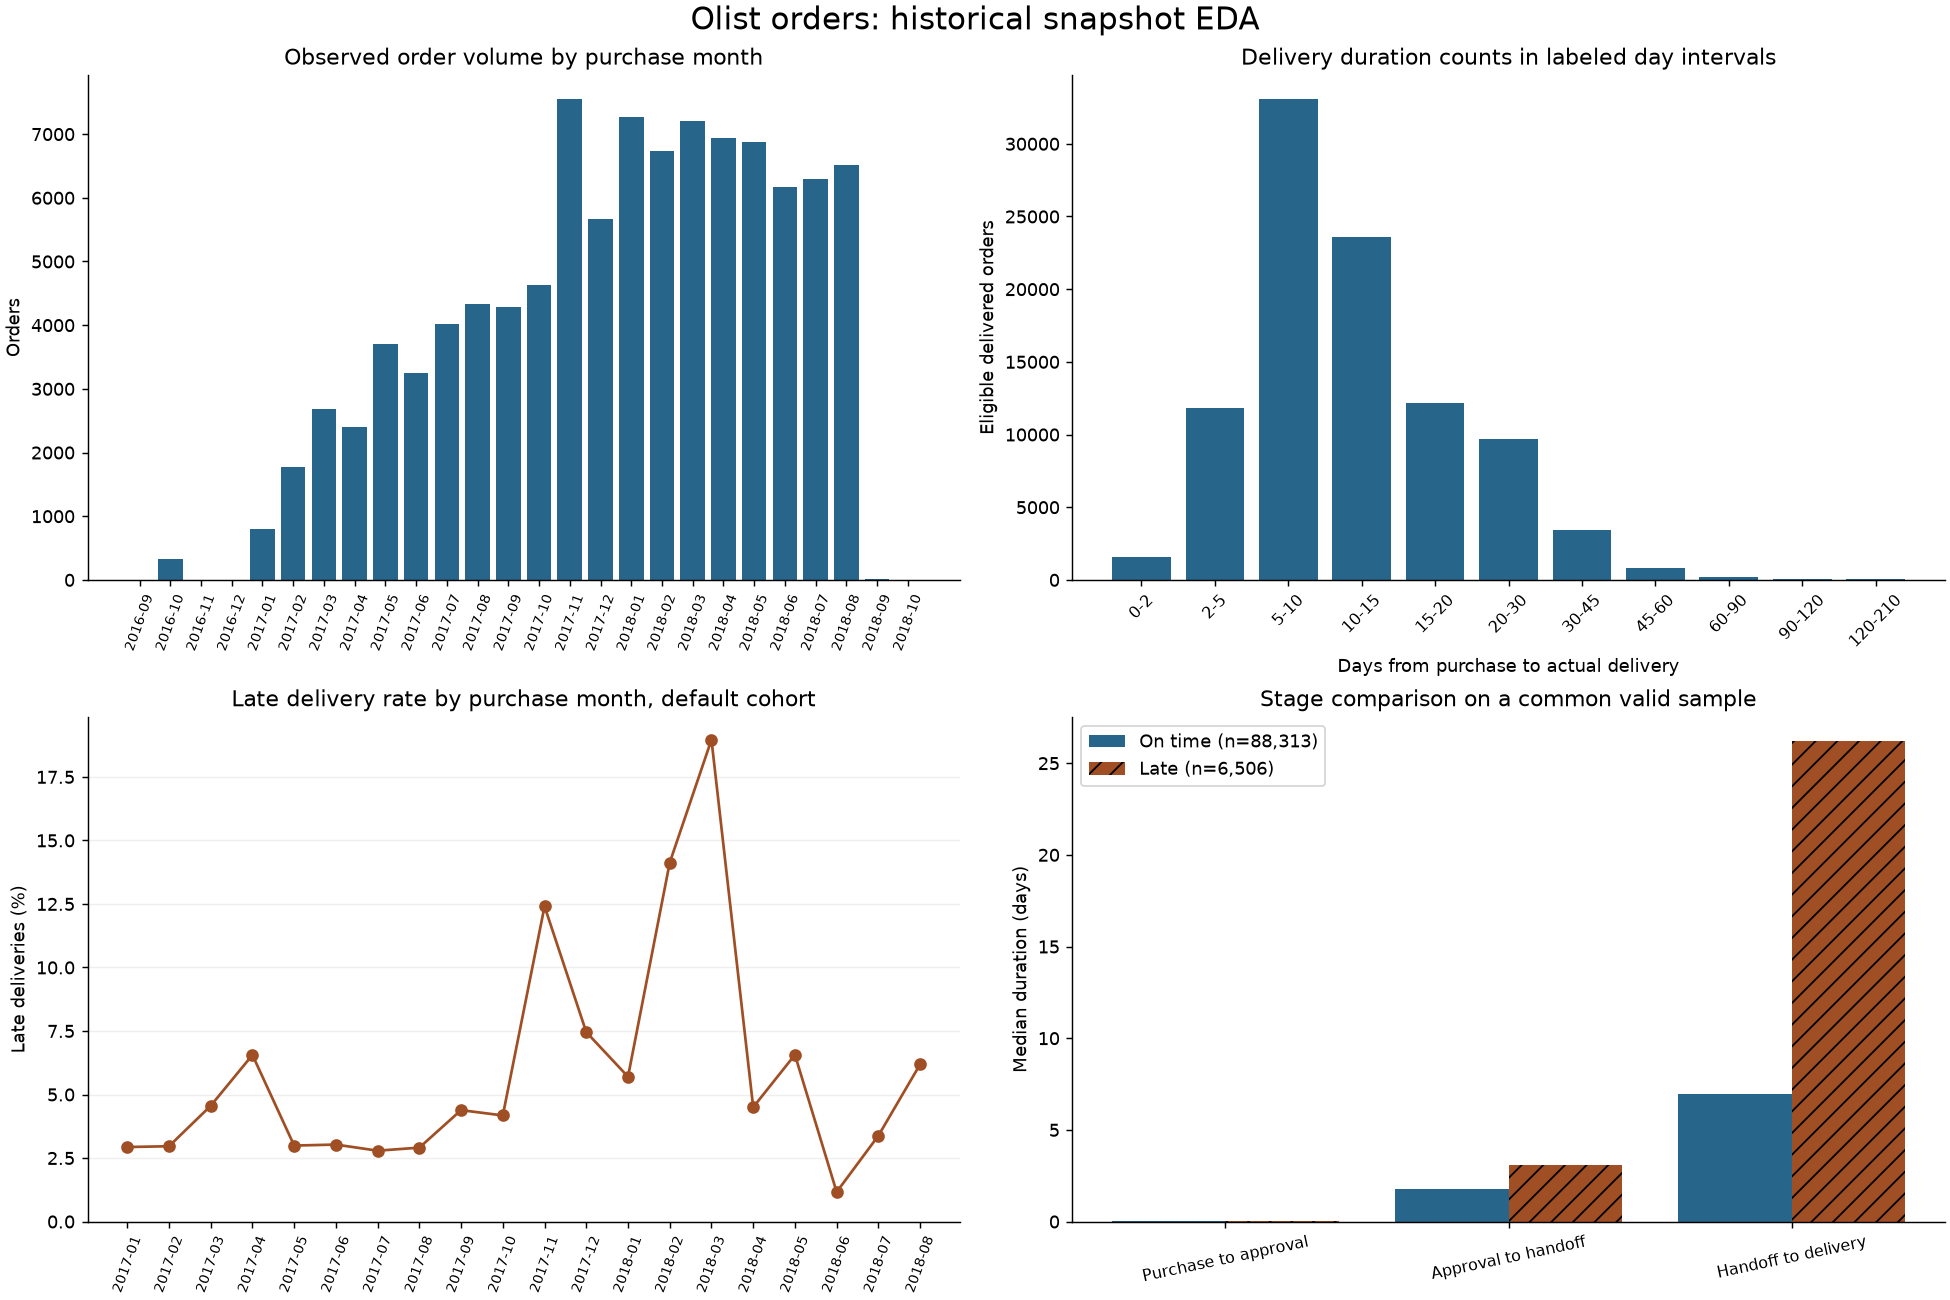

In [5]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

labels = purchase_counts.index.astype(str)
axes[0,0].bar(labels, purchase_counts.values, color="#27658a")
axes[0,0].set_title("Observed order volume by purchase month")
axes[0,0].set_ylabel("Orders")
axes[0,0].tick_params(axis="x", rotation=70, labelsize=8)

bins = [0, 2, 5, 10, 15, 20, 30, 45, 60, 90, 120, 210]
hist_counts, _ = np.histogram(valid.delivery_days, bins=bins)
hist_labels = [f"{a}-{b}" for a,b in zip(bins[:-1],bins[1:])]
axes[0,1].bar(hist_labels, hist_counts, color="#27658a")
axes[0,1].set_title("Delivery duration counts in labeled day intervals")
axes[0,1].set_xlabel("Days from purchase to actual delivery")
axes[0,1].set_ylabel("Eligible delivered orders")
axes[0,1].tick_params(axis="x", rotation=45, labelsize=9)
assert int(hist_counts.sum()) == len(valid)

axes[1,0].plot(monthly.index.astype(str), monthly.late_rate_pct, color="#a04e24", marker="o")
axes[1,0].set_title("Late delivery rate by purchase month, default cohort")
axes[1,0].set_ylabel("Late deliveries (%)")
axes[1,0].set_ylim(bottom=0)
axes[1,0].tick_params(axis="x", rotation=70, labelsize=8)
axes[1,0].grid(axis="y", alpha=.2)

stage_labels = ["Purchase to approval", "Approval to handoff", "Handoff to delivery"]
pos = np.arange(3)
axes[1,1].bar(pos-.2, stage_medians.loc["On time"], width=.4, color="#27658a", label="On time (n=88,313)")
axes[1,1].bar(pos+.2, stage_medians.loc["Late"], width=.4, color="#a04e24", hatch="//", label="Late (n=6,506)")
axes[1,1].set_xticks(pos, stage_labels)
axes[1,1].set_ylabel("Median duration (days)")
axes[1,1].set_title("Stage comparison on a common valid sample")
axes[1,1].legend()
axes[1,1].tick_params(axis="x", rotation=12, labelsize=9)

fig.suptitle("Olist orders: historical snapshot EDA", fontsize=17)
plt.show()


## Dashboard implications

- The selected orders table supports fulfillment monitoring; sales, margin, geography, carrier and product comparisons need other tables.
- Use total orders, late delivery rate and median end-to-end delivery days as three headlines.
- Show purchase-month late rates with denominator information and a valid-sample stage comparison.
- Use a purchase-date filter. Keep status filtering out of the global KPI controls.
- Do not infer current overdue orders from historical statuses or substitute the computer's current date for an unknown extraction date.
- This file has 99,441 distinct customer_id values, but the official customer table documentation says customer_id is order-specific.
  Repeat purchases need customer_unique_id from the customers table.
- Business workflows, hourly production refresh and example action thresholds in README.md are design assumptions, not measured Olist practices.
